In [1]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

df = pd.read_csv("index.csv")
d = np.load("features_r21d_aug.npz")
Xw, clip, flip = d["feats"], d["clip"], d["flip"]

# каждое окно наследует метку, группу и split своего клипа
yw = df.label.values[clip]
gw = df.source.values[clip]
sw = df.split.values[clip]

tr = sw != "test"                 # все окна + отражения train/val клипов
te = (sw == "test") & ~flip       # тест: только оригинальные окна
print(Xw.shape, tr.sum(), te.sum())

(656, 512) 470 93


In [2]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
candidates = {
    "LogReg": (LogisticRegression(max_iter=5000, class_weight="balanced"),
               {"clf__C": [0.001, 0.01, 0.1, 1]}),
    "SVM linear": (SVC(kernel="linear", class_weight="balanced"),
                   {"clf__C": [0.001, 0.01, 0.1, 1]}),
}

rows, preds = [], {}
for name, (est, grid) in candidates.items():
    gs = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("clf", est)]),
                      grid, cv=cv, scoring="balanced_accuracy")
    gs.fit(Xw[tr], yw[tr], groups=gw[tr])

    # решение для клипа: среднее решений по его окнам (>0 -> drink)
    s = pd.Series(gs.decision_function(Xw[te])).groupby(clip[te]).mean()
    pred = (s > 0).astype(int).values
    y_true = df.label.values[s.index]
    preds[name] = (y_true, pred)
    rows.append({"model": name, "params": gs.best_params_, "cv_bal_acc": gs.best_score_,
                 "test_acc": accuracy_score(y_true, pred),
                 "test_bal_acc": balanced_accuracy_score(y_true, pred),
                 "test_f1_macro": f1_score(y_true, pred, average="macro")})

res = pd.DataFrame(rows).round(3)
res.to_csv("results_r21d_aug.csv", index=False)
print(res.to_string())

        model             params  cv_bal_acc  test_acc  test_bal_acc  test_f1_macro
0      LogReg  {'clf__C': 0.001}       0.719     0.838         0.824           0.83
1  SVM linear  {'clf__C': 0.001}       0.721     0.788         0.777           0.78


SVM linear
              precision    recall  f1-score   support

         eat       0.77      0.71      0.74        34
       drink       0.80      0.85      0.82        46

    accuracy                           0.79        80
   macro avg       0.79      0.78      0.78        80
weighted avg       0.79      0.79      0.79        80



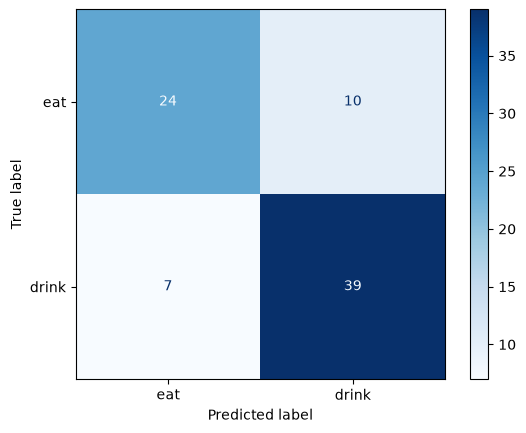

In [3]:
best = res.sort_values("cv_bal_acc").iloc[-1].model
y_true, pred = preds[best]
print(best)
print(classification_report(y_true, pred, target_names=["eat", "drink"]))
ConfusionMatrixDisplay.from_predictions(y_true, pred, display_labels=["eat", "drink"], cmap="Blues");